# 第三次作业｜12 类语种分类与中英混排识别

**实验目的**：使用 PyTorch 实现语言分类，将课堂的 RNN 作为基准，并尝试字符卷积网络（Char-CNN）提升语种识别能力。

本 Notebook 与根目录的 **`train.py`（完整训练入口）**、**`predict.py`（自由文本预测入口）** 配套，可以直接在 GitHub 预览。

> 实验区分两种模型：**快速训练演示模型**（Notebook 内只训练少量样本/少量轮次）和**正式实验模型**（加载此前训练完成的 `.pt` 权重）。以下所有正式测试指标都来自后者，不能把两个实验的数值混为一谈。

## 1. 环境检查与数据导入

按 `README.md` 安装 `torch`、`numpy`、`matplotlib`、`notebook`、`ipykernel`。`langid_core.py`、`data/`、`models/` 应当与 Notebook 在同一级目录。

In [1]:
from pathlib import Path
import collections
import sys
import numpy as np
import matplotlib.pyplot as plt
import torch

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'langid_core.py').exists():
    raise FileNotFoundError('请在 week03 工程目录中启动 Jupyter Notebook')
sys.path.insert(0, str(PROJECT_ROOT))

from langid_core import (ROOT, LABELS, LABEL_NAMES, read_rows, build_vocab, normalize,
                         LanguageDataset, create_model, load_model, predict_proba,
                         metrics_from_prob, seed_all)
from evaluate import TEACHER_MIXED, EXTRA_MIXED

torch.set_num_threads(1)
print('Python:', sys.version.split()[0])
print('PyTorch:', torch.__version__)
print('CUDA available:', torch.cuda.is_available())
print('项目目录:', ROOT)

Python: 3.13.5
PyTorch: 2.10.0+cpu
CUDA available: False
项目目录: /mnt/data/week03_12语种识别_提交版


## 2. 数据规模与类别均衡性

数据来自课堂提供的 Tatoeba 语料。训练集用于学习、验证集用于模型选择、测试集用于最终评估。字符词表严格从**训练集**构建。

In [2]:
train_rows = read_rows(ROOT / 'data/train.csv')
dev_rows = read_rows(ROOT / 'data/dev.csv')
test_rows = read_rows(ROOT / 'data/test.csv')

for title, rows in [('训练集', train_rows), ('验证集', dev_rows), ('测试集', test_rows)]:
    counts = collections.Counter(row['label'] for row in rows)
    print(f'{title}: {len(rows):,} 条；{len(counts)} 类；每类最少 {min(counts.values())}、最多 {max(counts.values())}')

print('随机查看几个语言样本：')
for lab in ['zh', 'en', 'ja', 'es', 'pt', 'ru']:
    row = next(r for r in train_rows if r['label'] == lab)
    print(f' {lab:2s} ({LABEL_NAMES[lab]:<5}): {row["text"][:90]}')

训练集: 9,600 条；12 类；每类最少 800、最多 800
验证集: 1,200 条；12 类；每类最少 100、最多 100
测试集: 1,800 条；12 类；每类最少 150、最多 150
随机查看几个语言样本：
 zh (中文   ): 我这样想是对的吗？
 en (英语   ): She said she had a difficult day.
 ja (日语   ): 彼は不公平な扱いを受けていると不平を言った。
 es (西班牙语 ): Eso tiene una pinta realmente horrible.
 pt (葡萄牙语 ): Você não é claustrofóbico?
 ru (俄语   ): Странный он, правда?


## 3. 文本预处理与模型结构

- Unicode NFKC 归一化、统一小写，保留**字母和组合标记**，去掉标点、数字和 Emoji；
- 用训练集构建字符词表；`<PAD>=0`，`<UNK>=1`；文本统一截断或补齐到 80 个字符；
- **课堂对照 RNN**：Embedding → RNN → 掩码最大池化 → LayerNorm → Dropout → Linear；
- **改进 Char-CNN**：Embedding → 多尺度 Conv1d(3/5/7) → 掩码最大/平均池化 → LayerNorm → 全连接层 → 12 类 logits。

训练用 `CrossEntropyLoss(logits, label)`，无需在计算交叉熵之前手动调用 Softmax。

In [3]:
train_vocab, char_counts = build_vocab(train_rows)
print('词表总大小:', len(train_vocab))
sentence = '这个 Transformer model 的 loss 为什么一直降不下去？'
print('预处理前:', sentence)
print('预处理后:', normalize(sentence))

rnn_preview = create_model('rnn', len(train_vocab))
cnn_preview = create_model('cnn', len(train_vocab))
print('RNN 参数量:', f'{sum(p.numel() for p in rnn_preview.parameters()):,}')
print('Char-CNN 参数量:', f'{sum(p.numel() for p in cnn_preview.parameters()):,}')
print('单条句子的模型输出维数:', tuple(cnn_preview(torch.zeros(1, 80, dtype=torch.long)).shape))
del rnn_preview, cnn_preview

词表总大小: 3276
预处理前: 这个 Transformer model 的 loss 为什么一直降不下去？
预处理后: 这个transformermodel的loss为什么一直降不下去


RNN 参数量: 218,892
Char-CNN 参数量: 378,668
单条句子的模型输出维数: (1, 12)


## 4. 两轮快速训练演示（学习 `train.py` 的核心过程）

从每种语言的训练集中抽取 **80 条**（共 960 条），只训练 2 轮来展示**前向传播、交叉熵、反向传播和 AdamW 更新**。该模型不保存为最终权重，**其得分不用于正式测试表**。正式训练使用完整数据，代码见 `train.py`。

In [4]:
from torch import nn
from torch.utils.data import DataLoader

seed_all(42)
mini_rows = [row for lab in LABELS for row in [r for r in train_rows if r['label'] == lab][:80]]
mini_loader = DataLoader(LanguageDataset(mini_rows, train_vocab, max_len=80, augment=True, seed=42),
                         batch_size=96, shuffle=True, num_workers=0)
mini_model = create_model('cnn', len(train_vocab))  # 演示模型，独立于正式预训练权重
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(mini_model.parameters(), lr=1e-3)
mini_history = []
for epoch in range(1, 3):
    mini_model.train()
    total_loss = 0.0
    for features, target in mini_loader:
        optimizer.zero_grad(set_to_none=True)
        logits = mini_model(features)
        loss = criterion(logits, target)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(mini_model.parameters(), max_norm=1.0)
        optimizer.step()
        total_loss += loss.item() * len(target)
    mean_loss = total_loss / len(mini_rows)
    mini_history.append(mean_loss)
    print(f'快速演示 Epoch {epoch}/2, train_loss={mean_loss:.4f}')

快速演示 Epoch 1/2, train_loss=2.2881


快速演示 Epoch 2/2, train_loss=1.6601


## 5. 加载正式训练权重，对标准测试集进行真实评价

`models/charcnn_aug_v2.pt` 为此前完成训练并保存的权重；`models/rnn_baseline.pt` 为课堂 RNN 结构对照组。完整训练脚本使用 **9,600 条样本**，验证集依据 **Macro-F1** 选择保存的模型。

In [5]:
reference_model, reference_ckpt = load_model(ROOT / 'models/rnn_baseline.pt')
final_model, final_ckpt = load_model(ROOT / 'models/charcnn_aug_v2.pt')

reference_proba = predict_proba(reference_model, [r['text'] for r in test_rows], reference_ckpt['vocab'], reference_ckpt['max_len'])
final_proba = predict_proba(final_model, [r['text'] for r in test_rows], final_ckpt['vocab'], final_ckpt['max_len'])
reference_metrics = metrics_from_prob(reference_proba, test_rows)
final_metrics = metrics_from_prob(final_proba, test_rows)

print('模型                 Accuracy        Macro-F1')
print(f'RNN 基准              {reference_metrics["accuracy"]:8.2%}        {reference_metrics["macro_f1"]:8.2%}')
print(f'Char-CNN 改进模型     {final_metrics["accuracy"]:8.2%}        {final_metrics["macro_f1"]:8.2%}')
print('测试样本总数:', len(test_rows))

模型                 Accuracy        Macro-F1
RNN 基准                94.50%          94.47%
Char-CNN 改进模型       97.22%          97.21%
测试样本总数: 1800


## 6. 困难集对比与混淆矩阵

对比极短句、去重音文本以及去掉假名后的日语。**日语去假名场景在理论上就可能与中文共享汉字，属于信息损失问题**，因此这部分不保证取得很高准确率。

short      n= 600 | RNN=82.33% | Char-CNN=90.17%


nodeaccent n= 600 | RNN=68.33% | Char-CNN=80.17%
nokana     n= 100 | RNN=24.00% | Char-CNN=22.00%


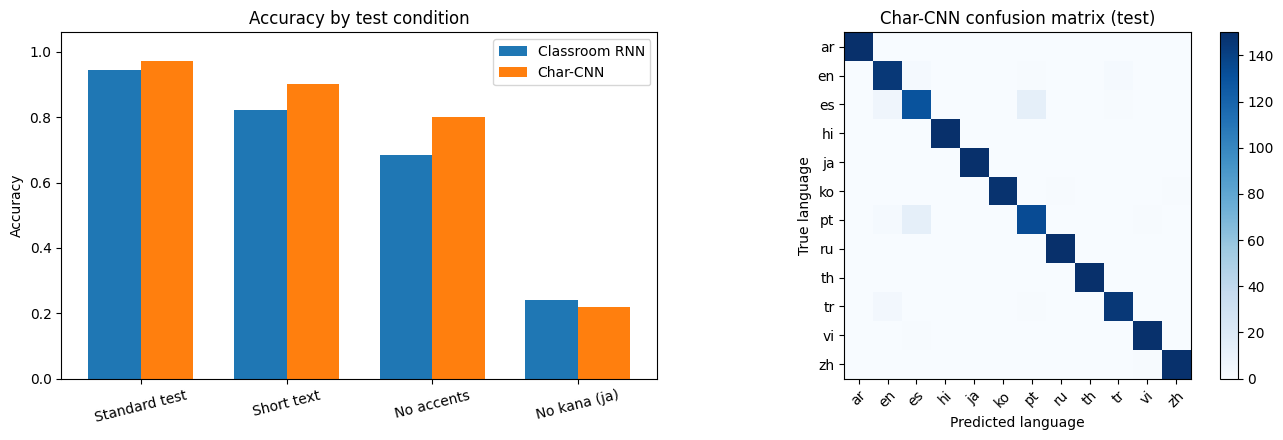

In [6]:
hard_rows = read_rows(ROOT / 'data/test_hard.csv')
results = {}
for slice_name in ['short', 'nodeaccent', 'nokana']:
    rows = [r for r in hard_rows if r['slice'] == slice_name]
    rnn_probs = predict_proba(reference_model, [r['text'] for r in rows], reference_ckpt['vocab'], reference_ckpt['max_len'])
    cnn_probs = predict_proba(final_model, [r['text'] for r in rows], final_ckpt['vocab'], final_ckpt['max_len'])
    rnn_acc = metrics_from_prob(rnn_probs, rows)['accuracy']
    cnn_acc = metrics_from_prob(cnn_probs, rows)['accuracy']
    results[slice_name] = (len(rows), rnn_acc, cnn_acc)
    print(f'{slice_name:10s} n={len(rows):4d} | RNN={rnn_acc:.2%} | Char-CNN={cnn_acc:.2%}')

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
compare_names = ['Standard test', 'Short text', 'No accents', 'No kana (ja)']
rnn_scores = [reference_metrics['accuracy']] + [results[k][1] for k in ['short', 'nodeaccent', 'nokana']]
cnn_scores = [final_metrics['accuracy']] + [results[k][2] for k in ['short', 'nodeaccent', 'nokana']]
x = np.arange(len(compare_names))
axes[0].bar(x - .18, rnn_scores, width=.36, label='Classroom RNN')
axes[0].bar(x + .18, cnn_scores, width=.36, label='Char-CNN')
axes[0].set_xticks(x, compare_names, rotation=14)
axes[0].set_ylabel('Accuracy')
axes[0].set_ylim(0, 1.06)
axes[0].legend()
axes[0].set_title('Accuracy by test condition')

confusion = np.asarray(final_metrics['confusion'])
img = axes[1].imshow(confusion, cmap='Blues')
axes[1].set_xticks(range(12), LABELS, rotation=45)
axes[1].set_yticks(range(12), LABELS)
axes[1].set_xlabel('Predicted language')
axes[1].set_ylabel('True language')
axes[1].set_title('Char-CNN confusion matrix (test)')
fig.colorbar(img, ax=axes[1], fraction=.045)
fig.tight_layout()
plt.show()

## 7. 课程混排样例与补充样例实测

以下用例属于**人工构造的诊断样本**，不是大规模真实分布下的泛化评估。训练集带随机英文技术词插入增强，主要意图是提高以中文为主的混排文本鲁棒性，但仍存在失败案例。

In [7]:
for title, cases in [('课程混排例句（20条）', TEACHER_MIXED), ('补充混排例句（16条）', EXTRA_MIXED)]:
    outputs = predict_proba(final_model, [s for s, _ in cases], final_ckpt['vocab'], final_ckpt['max_len'])
    prediction = [LABELS[int(p.argmax())] for p in outputs]
    num_correct = sum(pred == truth for pred, (_, truth) in zip(prediction, cases))
    print(f'{title}：正确 {num_correct}/{len(cases)}')
    for (text, truth), pred in zip(cases, prediction):
        if pred != truth:
            print(f'  误判 {truth} → {pred}：{text}')

课程混排例句（20条）：正确 19/20
  误判 zh → ja：先 git commit 再 push 上去，别直接改 master
补充混排例句（16条）：正确 15/16
  误判 pt → es：O novo modelo funciona bem com python


## 8. 任意输入预测：与 `predict.py` 一致

修改 `user_text` 后重新执行本单元格。模型输出的是 Softmax 分数，不是经过校准的真实置信度。

In [8]:
user_text = '这段 Python code 的运行结果很奇怪，我要重新检查一下'
probs = predict_proba(final_model, [user_text], final_ckpt['vocab'], final_ckpt['max_len'])[0]
print('输入句子:', user_text)
for i in np.argsort(probs)[::-1][:3]:
    print(f'  {LABEL_NAMES[LABELS[i]]} ({LABELS[i]}): {probs[i]:.2%}')

输入句子: 这段 Python code 的运行结果很奇怪，我要重新检查一下
  中文 (zh): 99.99%
  韩语 (ko): 0.01%
  日语 (ja): 0.00%


## 9. 总结与复现

- **准确率**：正式权重在 1,800 条标准测试集上达到 **97.22%**，对照 RNN 为 **94.50%**；标准测试 Macro-F1 为 **97.21%**。
- **技术特点**：多卷积核捕捉不同尺度的字符组合；仅对训练集引入英文术语增强；使用验证集选择最优权重。
- **局限性**：去假名日语明显受影响；西班牙语与葡萄牙语相近；大量英文命令的中文句子仍可能误判。模型不支持语言的逐词分割和可靠的未知语种拒识。
- **已有训练日志**：卷积网络实际留存 2 个阶段、共 4 个已记录轮次（`outputs/train_cnn_aug.log`、`outputs/train_cnn_aug_v2.log`）。本 Notebook 第 4 节的快速演示是额外教学示范，并非正式训练的轮次。

本目录提供可独立运行的脚本：

```bash
python predict.py --text "把 config 里的 learning rate 调小一点再跑"
python evaluate.py --model models/charcnn_aug_v2.pt
python train.py --arch cnn --augment --epochs 24 --output models/retrained.pt
```

详细的依赖环境、运行方法与完整结果请见 `README.md`。数据来源和许可见 `data/DATA_CARD.md`。